# Copper Filament Density Comparison by Thermal Cycle

This notebook compares the available green and sintered densities for the Virtual Foundry copper filament series. Missing measurements in the supplied table are retained as missing values rather than inferred.

Two populations are kept separate:

- **Printed specimens:** cycle- and filament-level means with standard-deviation error bars where repeated measurements are available.
- **Filament references:** rows explicitly labelled `Filament VF1`, `Filament VF2`, or `Filament VF3` in the supplied table.


## 1. Setup


In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import numpy as np
import pandas as pd

from notebook_plot_saver import configure_notebook_plot_saving

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "notebook_plot_saver.py").exists():
    PROJECT_ROOT = PROJECT_ROOT / "3D_Printing_Project"

FIGURE_ROOT = configure_notebook_plot_saving(
    PROJECT_ROOT / "notebook_figures",
    dpi=300,
    default_series="09_Copper_Filament_Comparison",
)

CYCLE_ORDER = [
    "DS1 / DS1",
    "D2 / S1 (N2/CO2/N2)",
    "D2 / S1 (CO2)",
    "DS2 / DS2",
    "DS3 / DS3",
    "DS4 / DS4",
    "DS5 / DS5",
]
CYCLE_LABELS = {
    "DS1 / DS1": "$\\mathbf{DS1\\ /\\ DS1}$\nCO2\n1052\N{DEGREE SIGN}C\n(10 h)",
    "D2 / S1 (N2/CO2/N2)": "$\\mathbf{D2\\ /\\ S1}$\nN2/CO2/N2\n1045\N{DEGREE SIGN}C\n(5 h)",
    "D2 / S1 (CO2)": "$\\mathbf{D2\\ /\\ S1}$\nCO2\n1045\N{DEGREE SIGN}C\n(5 h)",
    "DS2 / DS2": "$\\mathbf{DS2\\ /\\ DS2}$\nN2/CO2\n1048\N{DEGREE SIGN}C\n(6 h)",
    "DS3 / DS3": "$\\mathbf{DS3\\ /\\ DS3}$\nN2/CO2\n1050\N{DEGREE SIGN}C\n(7 h)",
    "DS4 / DS4": "$\\mathbf{DS4\\ /\\ DS4}$\nN2/CO2\n1052\N{DEGREE SIGN}C\n(7 h)",
    "DS5 / DS5": "$\\mathbf{DS5\\ /\\ DS5}$\nN2/CO2\n1052\N{DEGREE SIGN}C\n(7 h)",
}
FILAMENT_ORDER = ["VF1", "VF2", "VF3"]

GREEN_COLORS = {
    "VF1": "#6FA87A",  # Dark green shade.
    "VF2": "#91BE79",  # Medium green shade.
    "VF3": "#B7D2A0",  # Light green shade.
}
GREEN_ACCENT_COLORS = {
    "VF1": "#1F5F35",
    "VF2": "#3F762F",
    "VF3": "#587538",
}
SINTERED_COLORS = {
    "VF1": "#B85C2B",  # Brown-orange shade.
    "VF2": "#E58A3A",  # Orange shade.
    "VF3": "#F1B96E",  # Light orange shade.
}
SINTERED_ACCENT_COLORS = {
    "VF1": "#743318",
    "VF2": "#A95518",
    "VF3": "#8A581F",
}
GREEN_BAR_EDGE_COLOR = "#2F6F2A"
SINTERED_BAR_EDGE_COLOR = "#7A4A21"

print(f"Figures: {FIGURE_ROOT}")


Figures: C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\notebook_figures


## 2. Transcribed Density Data

The density values below are transcribed from the supplied comparison table. Cycle conditions are stored separately from the short cycle names used on the x-axis.


In [2]:
CYCLE_CONDITIONS = pd.DataFrame([
    {"cycle_name": "DS1 / DS1", "debinding": "480 deg C, 4 h, CO2", "sintering": "1052 deg C, 10 h, CO2"},
    {"cycle_name": "D2 / S1 (N2/CO2/N2)", "debinding": "481 deg C, 4 h, Ar", "sintering": "1045 deg C, 5 h, N2/CO2/N2"},
    {"cycle_name": "D2 / S1 (CO2)", "debinding": "481 deg C, 4 h, Ar", "sintering": "1045 deg C, 5 h, CO2"},
    {"cycle_name": "DS2 / DS2", "debinding": "490 deg C, 5 h, N2", "sintering": "1048 deg C, 6 h, N2/CO2"},
    {"cycle_name": "DS3 / DS3", "debinding": "490 deg C, 5 h, N2", "sintering": "1050 deg C, 7 h, N2/CO2"},
    {"cycle_name": "DS4 / DS4", "debinding": "480 deg C, 5 h, N2", "sintering": "1052 deg C, 7 h, N2/CO2"},
    {"cycle_name": "DS5 / DS5", "debinding": "DS5; details not supplied", "sintering": "1052 deg C, 7 h, N2/CO2"},
])

# D2/S1 CO2: retain the first spreadsheet density and use 0.074 g water weight for replicate 2.
D2_S1_CO2_DENSITIES = np.array([7.99, 0.63 / 0.074], dtype=float)
D2_S1_CO2_MEAN = float(D2_S1_CO2_DENSITIES.mean())
D2_S1_CO2_SD_PERCENT = float(
    D2_S1_CO2_DENSITIES.std(ddof=1) / D2_S1_CO2_MEAN * 100.0
)

DENSITY_RECORDS = [
    ("DS1 / DS1", "Filament VF1", "VF1", "filament reference", np.nan, 7.13),
    ("D2 / S1 (N2/CO2/N2)", "Filament VF2", "VF2", "filament reference", np.nan, 7.33),
    ("D2 / S1 (N2/CO2/N2)", "VF1_T17C", "VF1", "printed specimen", 4.76, 5.30),
    ("D2 / S1 (N2/CO2/N2)", "VF1_P4", "VF1", "printed specimen", 4.62, 5.77),
    ("D2 / S1 (CO2)", "Filament VF2", "VF2", "filament reference", np.nan, D2_S1_CO2_MEAN),
    ("DS2 / DS2", "VF1_T1v2", "VF1", "printed specimen", np.nan, 5.68),
    ("DS2 / DS2", "VF1_T1v6", "VF1", "printed specimen", np.nan, 5.76),
    ("DS2 / DS2", "VF2_M01", "VF2", "printed specimen", np.nan, 7.18),
    ("DS2 / DS2", "VF2_D1.25", "VF2", "printed specimen", np.nan, 6.88),
    ("DS2 / DS2", "VF2_SF1.25", "VF2", "printed specimen", np.nan, 6.88),
    ("DS2 / DS2", "Filament VF2", "VF2", "filament reference", np.nan, 7.03),
    ("DS3 / DS3", "VF2_M02", "VF2", "printed specimen", 4.89, 7.14),
    ("DS3 / DS3", "VF2_M03", "VF2", "printed specimen", 4.91, 7.19),
    ("DS3 / DS3", "VF2_M04", "VF2", "printed specimen", 5.00, 7.28),
    ("DS3 / DS3", "VF2_M05", "VF2", "printed specimen", 5.06, 7.13),
    ("DS3 / DS3", "VF2_M06", "VF2", "printed specimen", 5.03, 7.32),
    ("DS3 / DS3", "VF2_M07", "VF2", "printed specimen", 4.99, 7.26),
    ("DS3 / DS3", "Filament VF1", "VF1", "filament reference", np.nan, 6.71),
    ("DS3 / DS3", "Filament VF2", "VF2", "filament reference", np.nan, 7.96),
    ("DS4 / DS4", "VF2_M08", "VF2", "printed specimen", 5.06, 7.17),
    ("DS4 / DS4", "VF2_M09", "VF2", "printed specimen", 4.92, 7.31),
    ("DS4 / DS4", "VF2_M10", "VF2", "printed specimen", 5.00, 7.12),
    ("DS4 / DS4", "VF2_DF1.5", "VF2", "printed specimen", np.nan, 6.24),
    ("DS4 / DS4", "VF1_T1", "VF1", "printed specimen", 4.62, 6.22),
    ("DS4 / DS4", "VF1_T2", "VF1", "printed specimen", 4.70, 6.49),
    ("DS4 / DS4", "VF1_T3", "VF1", "printed specimen", 4.45, 6.23),
    ("DS4 / DS4", "VF1_T5", "VF1", "printed specimen", 4.50, 6.37),
    ("DS4 / DS4", "VF1_T6", "VF1", "printed specimen", 4.43, 8.54),
    ("DS4 / DS4", "Filament VF1", "VF1", "filament reference", np.nan, 7.76),
    ("DS4 / DS4", "Filament VF2", "VF2", "filament reference", np.nan, 7.28),
    ("DS4 / DS4", "Filament VF3", "VF3", "filament reference", np.nan, 7.20),
    ("DS5 / DS5", "Filament VF2", "VF2", "filament reference", np.nan, 7.33),
    ("DS5 / DS5", "Filament VF3", "VF3", "filament reference", np.nan, 7.13),
]

density_data = pd.DataFrame(
    DENSITY_RECORDS,
    columns=[
        "cycle_name",
        "specimen",
        "filament_type",
        "sample_class",
        "green_density_g_cm3",
        "sintered_density_g_cm3",
    ],
)
SINTERED_REFERENCE_MEASUREMENTS = {
    ("DS1 / DS1", "VF1"): ([7.13, 7.20, 7.06], 7.13, 0.80),
    ("D2 / S1 (N2/CO2/N2)", "VF2"): ([7.93, 6.74], 7.33, 9.38),
    ("D2 / S1 (CO2)", "VF2"): (
        D2_S1_CO2_DENSITIES.tolist(),
        D2_S1_CO2_MEAN,
        D2_S1_CO2_SD_PERCENT,
    ),
    ("DS2 / DS2", "VF2"): ([6.77, 7.29], 7.03, 4.11),
    ("DS3 / DS3", "VF1"): ([7.07, 6.28, 6.79], 6.71, 4.44),
    ("DS3 / DS3", "VF2"): ([8.29, 7.63], 7.96, 5.24),
    ("DS4 / DS4", "VF1"): ([8.54, 6.99], 7.76, 12.25),
    ("DS4 / DS4", "VF2"): ([8.51, 6.53, 6.80], 7.28, 11.98),
    ("DS4 / DS4", "VF3"): ([8.05, 6.36], 7.20, 13.38),
    ("DS5 / DS5", "VF2"): ([6.99, 7.67], 7.33, 5.37),
    ("DS5 / DS5", "VF3"): ([7.22, 7.05], 7.13, 1.39),
}
density_data["sintered_density_sd_g_cm3"] = np.nan
density_data["sintered_density_sd_percent"] = np.nan
density_data["sintered_n"] = 1
for (cycle_name, filament_type), measurement_data in (
    SINTERED_REFERENCE_MEASUREMENTS.items()
):
    replicate_values, mean_density, sd_percent = measurement_data
    replicate_values = np.asarray(replicate_values, dtype=float)
    replicate_mask = (
        density_data["cycle_name"].eq(cycle_name)
        & density_data["filament_type"].eq(filament_type)
        & density_data["sample_class"].eq("filament reference")
    )
    density_data.loc[replicate_mask, "sintered_density_g_cm3"] = (
        mean_density
    )
    density_data.loc[replicate_mask, "sintered_density_sd_g_cm3"] = (
        mean_density * sd_percent / 100.0
    )
    density_data.loc[replicate_mask, "sintered_density_sd_percent"] = sd_percent
    density_data.loc[replicate_mask, "sintered_n"] = len(replicate_values)
density_data["cycle_name"] = pd.Categorical(
    density_data["cycle_name"], categories=CYCLE_ORDER, ordered=True
)
GREEN_FILAMENT_REFERENCE_MEASUREMENTS = pd.DataFrame({
    "filament_type": ["VF1"] * 3 + ["VF2"] * 3 + ["VF3"] * 2 + ["MF"] * 2,
    "green_density_g_cm3": [
        4.72, 4.96, 4.88,
        5.57, 5.37, 5.56,
        4.56, 4.72,
        6.15, 6.33,
    ],
})
GREEN_FILAMENT_REFERENCE_DENSITIES = (
    GREEN_FILAMENT_REFERENCE_MEASUREMENTS
    .groupby("filament_type", sort=False)["green_density_g_cm3"]
    .agg(
        avg_green_density_g_cm3="mean",
        green_sd_g_cm3="std",
        green_n="count",
    )
    .reset_index()
)
green_density_map = GREEN_FILAMENT_REFERENCE_DENSITIES.set_index(
    "filament_type"
)["avg_green_density_g_cm3"]
reference_mask = density_data["sample_class"].eq("filament reference")
density_data.loc[reference_mask, "green_density_g_cm3"] = (
    density_data.loc[reference_mask, "filament_type"].astype(str).map(green_density_map)
)

density_data["filament_type"] = pd.Categorical(
    density_data["filament_type"], categories=FILAMENT_ORDER, ordered=True
)

display(CYCLE_CONDITIONS)
display(GREEN_FILAMENT_REFERENCE_MEASUREMENTS)
display(GREEN_FILAMENT_REFERENCE_DENSITIES.round(3))
display(density_data.sort_values(["cycle_name", "sample_class", "filament_type", "specimen"]))


,cycle_name,debinding,sintering
0,DS1 / DS1,"480 deg C, 4 h, CO2","1052 deg C, 10 h, CO2"
1,D2 / S1 (N2/CO2/N2),"481 deg C, 4 h, Ar","1045 deg C, 5 h, N2/CO2/N2"
2,D2 / S1 (CO2),"481 deg C, 4 h, Ar","1045 deg C, 5 h, CO2"
3,DS2 / DS2,"490 deg C, 5 h, N2","1048 deg C, 6 h, N2/CO2"
4,DS3 / DS3,"490 deg C, 5 h, N2","1050 deg C, 7 h, N2/CO2"
5,DS4 / DS4,"480 deg C, 5 h, N2","1052 deg C, 7 h, N2/CO2"
6,DS5 / DS5,DS5; details not supplied,"1052 deg C, 7 h, N2/CO2"


,filament_type,green_density_g_cm3
0,VF1,4.72
1,VF1,4.96
2,VF1,4.88
3,VF2,5.57
4,VF2,5.37
5,VF2,5.56
6,VF3,4.56
7,VF3,4.72
8,MF,6.15
9,MF,6.33


,filament_type,avg_green_density_g_cm3,green_sd_g_cm3,green_n
0,VF1,4.853,0.122,3
1,VF2,5.500,0.113,3
2,VF3,4.640,0.113,2
3,MF,6.240,0.127,2


,cycle_name,specimen,filament_type,sample_class,green_density_g_cm3,sintered_density_g_cm3,sintered_density_sd_g_cm3,sintered_density_sd_percent,sintered_n
0,DS1 / DS1,Filament VF1,VF1,filament reference,4.853333,7.13,0.057040,0.80,3
1,D2 / S1 (N2/CO2/N2),Filament VF2,VF2,filament reference,5.500000,7.33,0.687554,9.38,2
3,D2 / S1 (N2/CO2/N2),VF1_P4,VF1,printed specimen,4.620000,5.77,NaN,NaN,1
2,D2 / S1 (N2/CO2/N2),VF1_T17C,VF1,printed specimen,4.760000,5.30,NaN,NaN,1
4,D2 / S1 (CO2),Filament VF2,VF2,filament reference,5.500000,8.48,0.668224,7.88,2
10,DS2 / DS2,Filament VF2,VF2,filament reference,5.500000,7.03,0.288933,4.11,2
5,DS2 / DS2,VF1_T1v2,VF1,printed specimen,NaN,5.68,NaN,NaN,1
6,DS2 / DS2,VF1_T1v6,VF1,printed specimen,NaN,5.76,NaN,NaN,1
8,DS2 / DS2,VF2_D1.25,VF2,printed specimen,NaN,6.88,NaN,NaN,1
7,DS2 / DS2,VF2_M01,VF2,printed specimen,NaN,7.18,NaN,NaN,1


## 3. Cycle-level Printed-specimen Summary

Means and sample standard deviations are calculated independently for every cycle, filament type, and density state. Standard deviations are shown only when at least two measurements are available.


In [3]:
printed_specimens = density_data.query("sample_class == 'printed specimen'").copy()
printed_long = printed_specimens.melt(
    id_vars=["cycle_name", "specimen", "filament_type"],
    value_vars=["green_density_g_cm3", "sintered_density_g_cm3"],
    var_name="density_state",
    value_name="density_g_cm3",
).dropna(subset=["density_g_cm3"])
printed_long["density_state"] = printed_long["density_state"].map({
    "green_density_g_cm3": "Green density",
    "sintered_density_g_cm3": "Sintered density",
})

printed_summary = (
    printed_long.groupby(
        ["cycle_name", "filament_type", "density_state"],
        observed=True,
    )["density_g_cm3"]
    .agg(mean_density_g_cm3="mean", sd_density_g_cm3="std", n="count")
    .reset_index()
    .sort_values(["cycle_name", "filament_type", "density_state"])
)
display(printed_summary.round({"mean_density_g_cm3": 3, "sd_density_g_cm3": 3}))


,cycle_name,filament_type,density_state,mean_density_g_cm3,sd_density_g_cm3,n
0,D2 / S1 (N2/CO2/N2),VF1,Green density,4.690,0.099,2
1,D2 / S1 (N2/CO2/N2),VF1,Sintered density,5.535,0.332,2
2,DS2 / DS2,VF1,Sintered density,5.720,0.057,2
3,DS2 / DS2,VF2,Sintered density,6.980,0.173,3
4,DS3 / DS3,VF2,Green density,4.980,0.067,6
5,DS3 / DS3,VF2,Sintered density,7.220,0.078,6
6,DS4 / DS4,VF1,Green density,4.540,0.116,5
7,DS4 / DS4,VF1,Sintered density,6.770,0.996,5
8,DS4 / DS4,VF2,Green density,4.993,0.070,3
9,DS4 / DS4,VF2,Sintered density,6.960,0.487,4


## 4. Filament-reference Density Comparison

The figure combines filament-type green densities with cycle-resolved sintered densities. Green-density error bars show one sample standard deviation (`ddof=1`) across the repeated density measurements. Every sintered-filament bar uses the supplied average density and percentage deviation; the percentage deviation is converted to density units as `average density × deviation / 100` for the error bar. Dotted lines in the sintered panel show the mean sintered density of each filament type. Secondary axes express density relative to the theoretical density of copper (8.96 g/cm3).


Sintered filament-reference results: 11


,cycle_name,specimen,filament_type,sintered_density_g_cm3
0,DS1 / DS1,Filament VF1,VF1,7.13
17,DS3 / DS3,Filament VF1,VF1,6.71
28,DS4 / DS4,Filament VF1,VF1,7.76
1,D2 / S1 (N2/CO2/N2),Filament VF2,VF2,7.33
4,D2 / S1 (CO2),Filament VF2,VF2,8.48
10,DS2 / DS2,Filament VF2,VF2,7.03
18,DS3 / DS3,Filament VF2,VF2,7.96
29,DS4 / DS4,Filament VF2,VF2,7.28
31,DS5 / DS5,Filament VF2,VF2,7.33
30,DS4 / DS4,Filament VF3,VF3,7.20


,filament_type,green_density_g_cm3,green_sd_g_cm3,green_n,sintered_density_g_cm3,sintered_sd_g_cm3,sintered_n,green_relative_density_percent,sintered_relative_density_percent
0,VF1,4.85,0.12,3,7.20,0.53,3,54.17,80.36
1,VF2,5.50,0.11,3,7.57,0.54,6,61.38,84.47
2,VF3,4.64,0.11,2,7.16,0.05,2,51.79,79.97


C:\Users\sarklug\Documents\Visual Studio Code\3D_Printing_Project\notebook_plot_saver.py:128: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  return original_show(*args, **kwargs)


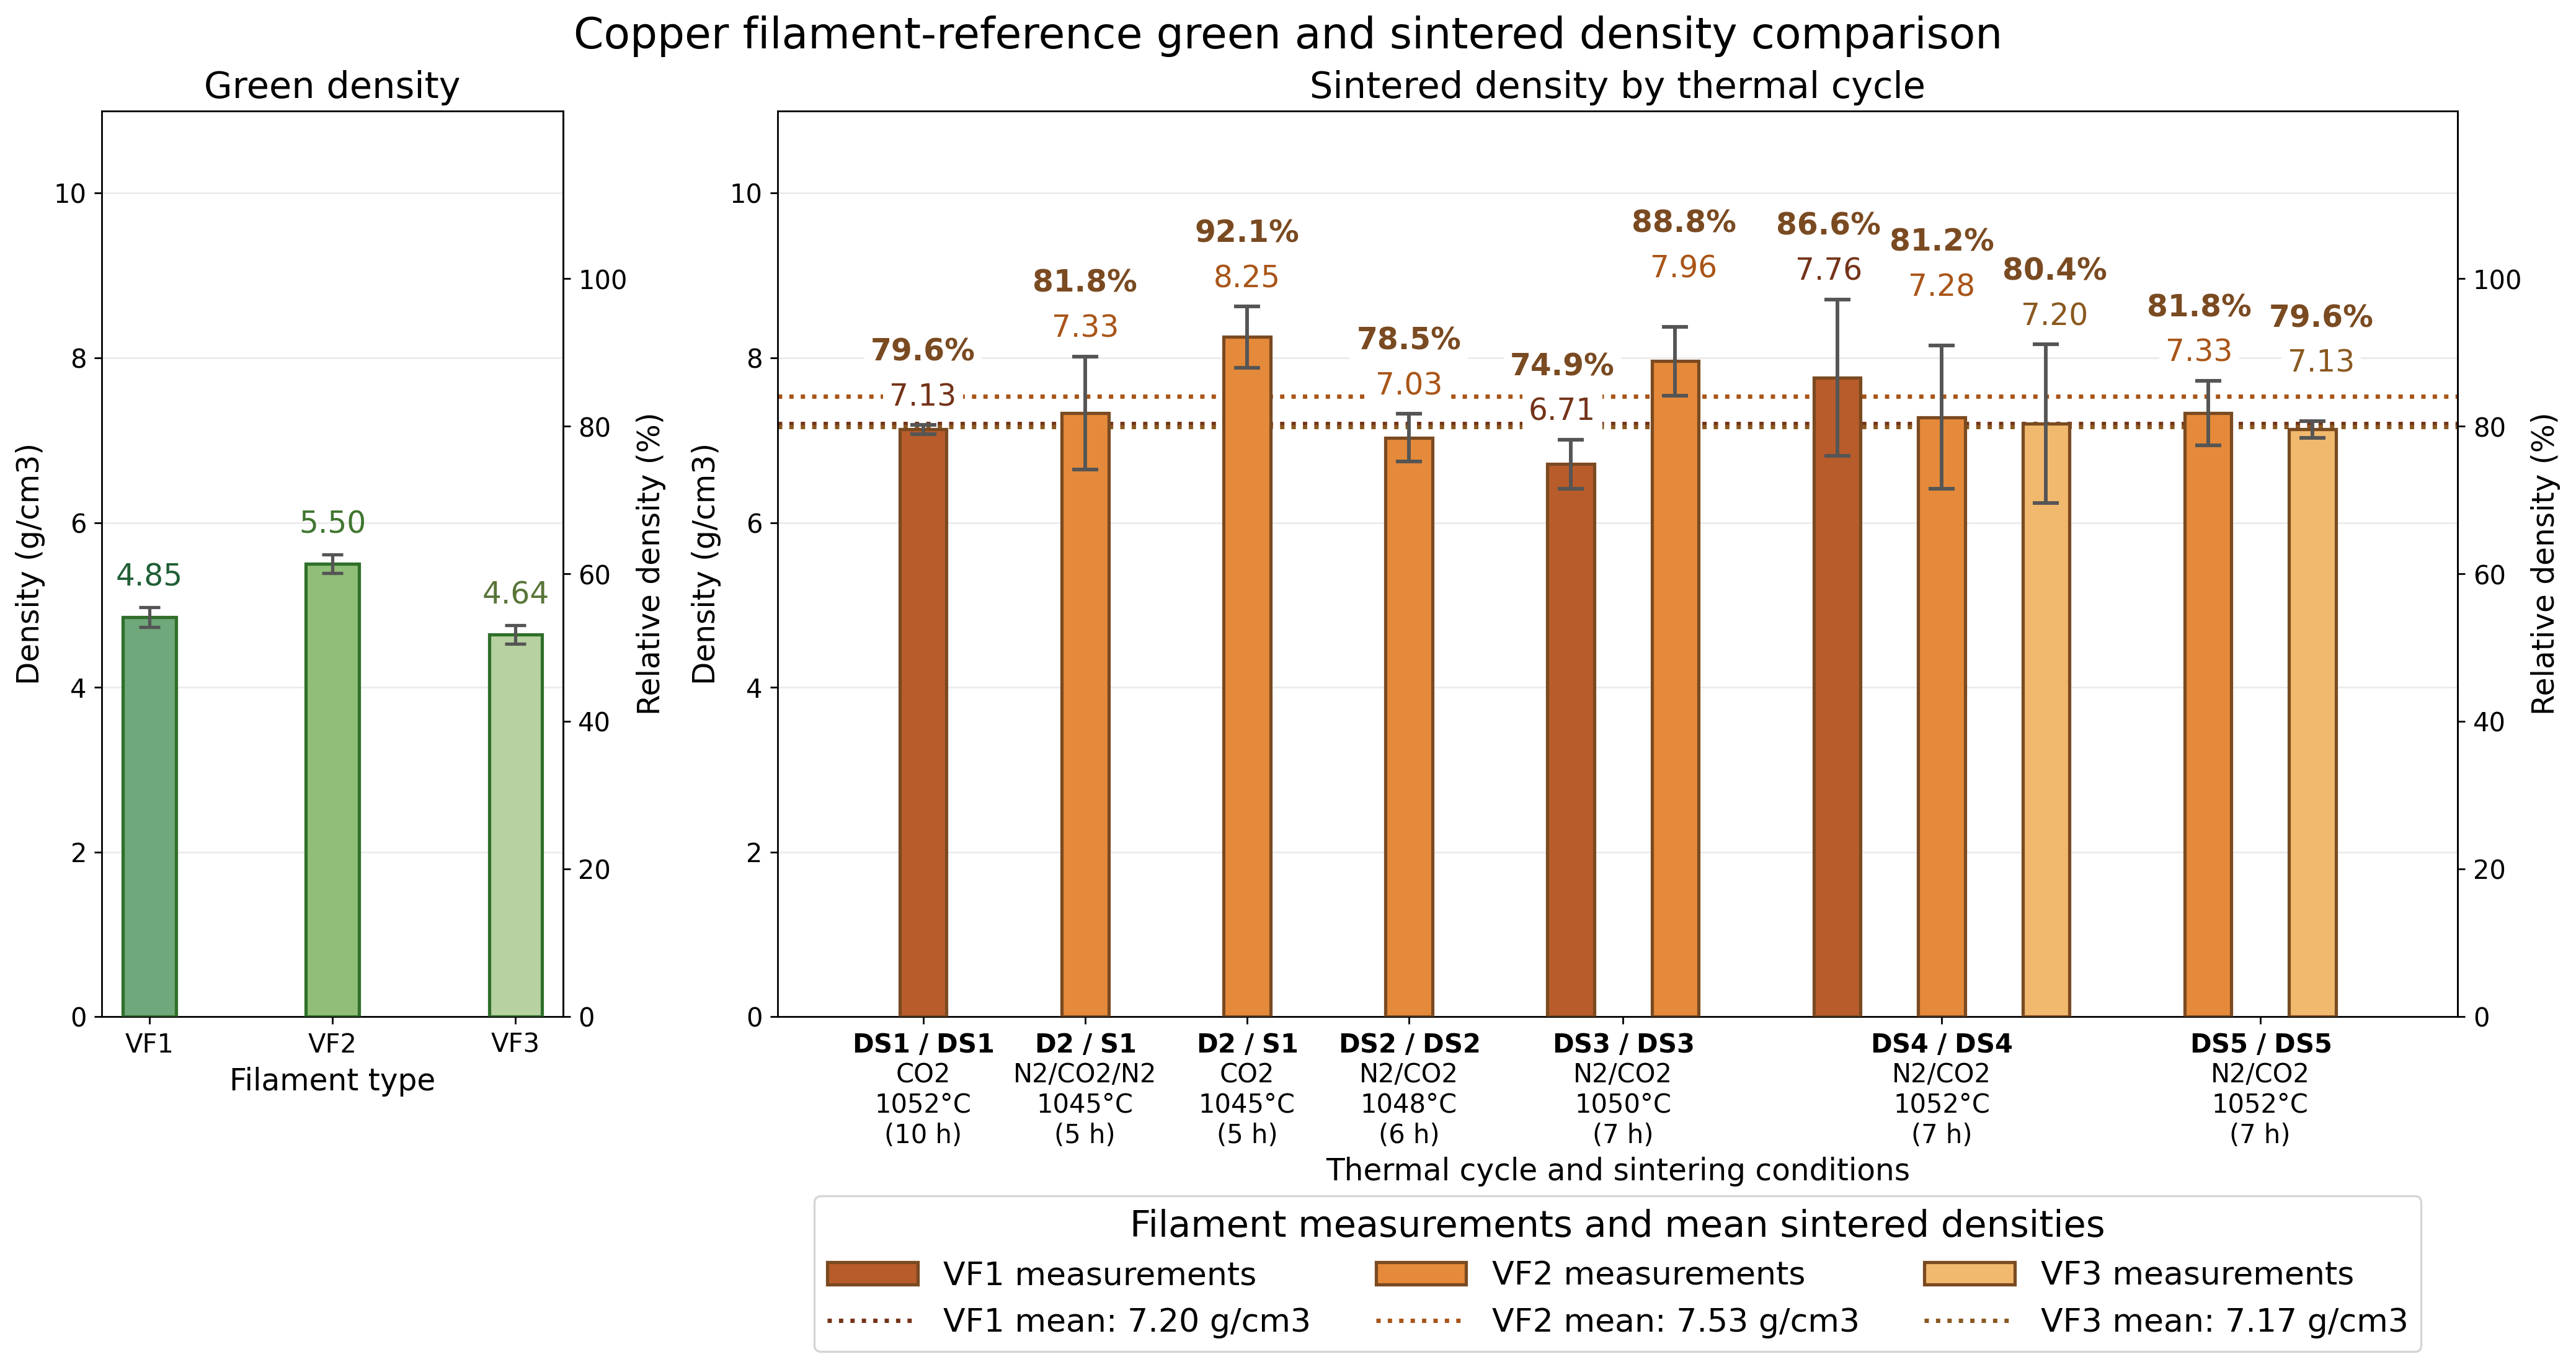

In [4]:
from matplotlib.lines import Line2D

THEORETICAL_COPPER_DENSITY_G_CM3 = 8.96

filament_references = density_data.query("sample_class == 'filament reference'").copy()
print(f"Sintered filament-reference results: {len(filament_references)}")

green_reference_summary = (
    GREEN_FILAMENT_REFERENCE_DENSITIES
    .query("filament_type in @FILAMENT_ORDER")
    .set_index("filament_type")
    .reindex(FILAMENT_ORDER)
)
sintered_summary = (
    filament_references
    .groupby("filament_type", observed=True)["sintered_density_g_cm3"]
    .agg(["mean", "std", "count"])
    .reindex(FILAMENT_ORDER)
)

filament_density_summary = pd.DataFrame({
    "filament_type": FILAMENT_ORDER,
    "green_density_g_cm3": green_reference_summary["avg_green_density_g_cm3"].to_numpy(dtype=float),
    "green_sd_g_cm3": green_reference_summary["green_sd_g_cm3"].to_numpy(dtype=float),
    "green_n": green_reference_summary["green_n"].to_numpy(dtype=int),
    "sintered_density_g_cm3": sintered_summary["mean"].to_numpy(dtype=float),
    "sintered_sd_g_cm3": sintered_summary["std"].to_numpy(dtype=float),
    "sintered_n": sintered_summary["count"].to_numpy(dtype=int),
})
filament_density_summary["green_relative_density_percent"] = (
    filament_density_summary["green_density_g_cm3"]
    / THEORETICAL_COPPER_DENSITY_G_CM3
    * 100.0
)
filament_density_summary["sintered_relative_density_percent"] = (
    filament_density_summary["sintered_density_g_cm3"]
    / THEORETICAL_COPPER_DENSITY_G_CM3
    * 100.0
)

display(filament_references[[
    "cycle_name",
    "specimen",
    "filament_type",
    "sintered_density_g_cm3",
]].sort_values(["filament_type", "cycle_name"]))
display(filament_density_summary.round(2))


def density_to_relative_percent(density):
    return density / THEORETICAL_COPPER_DENSITY_G_CM3 * 100.0


def relative_percent_to_density(relative_percent):
    return relative_percent / 100.0 * THEORETICAL_COPPER_DENSITY_G_CM3


COMPARISON_DENSITY_Y_LIMIT = 11.0
COMPARISON_DENSITY_TICKS = np.arange(0.0, 10.1, 2.0)


def style_density_axis(axis, title, y_limit):
    axis.set_title(title, fontsize=17, pad=6)
    axis.set_ylim(0, y_limit)
    axis.set_yticks(COMPARISON_DENSITY_TICKS)
    axis.set_axisbelow(True)
    axis.grid(axis="y", alpha=0.25, zorder=0)
    axis.tick_params(axis="both", labelsize=12)
    axis.set_ylabel("Density (g/cm3)", fontsize=14)

    relative_axis = axis.secondary_yaxis(
        "right",
        functions=(density_to_relative_percent, relative_percent_to_density),
    )
    relative_axis.set_ylabel("Relative density (%)", fontsize=14)
    relative_axis.tick_params(axis="y", labelsize=12)
    return relative_axis


figure, (green_axis, sintered_axis) = plt.subplots(
    1,
    2,
    figsize=(16.5, 8.7),
    gridspec_kw={"width_ratios": [0.70, 2.55]},
    constrained_layout=True,
)

# Green-density panel.
green_positions = np.arange(len(FILAMENT_ORDER), dtype=float)
green_values = filament_density_summary["green_density_g_cm3"].to_numpy(dtype=float)
green_sd_values = filament_density_summary["green_sd_g_cm3"].to_numpy(dtype=float)
green_bar_width = 0.29
green_bars = green_axis.bar(
    green_positions,
    green_values,
    width=green_bar_width,
    color=[GREEN_COLORS[filament_type] for filament_type in FILAMENT_ORDER],
    edgecolor=GREEN_BAR_EDGE_COLOR,
    linewidth=1.5,
    yerr=green_sd_values,
    error_kw={"ecolor": "#555555", "elinewidth": 1.5, "capsize": 5, "capthick": 1.5},
    zorder=3,
)
for bar, value, sd_value, filament_type in zip(
    green_bars, green_values, green_sd_values, FILAMENT_ORDER
):
    green_axis.annotate(
        f"{value:.2f}",
        (bar.get_x() + bar.get_width() / 2.0, value + sd_value),
        xytext=(0, 7), textcoords="offset points",
        ha="center", va="bottom",
        fontsize=14, fontweight="normal",
        color=GREEN_ACCENT_COLORS[filament_type],
    )
green_axis.set_xticks(green_positions, FILAMENT_ORDER)
green_axis.set_xlabel("Filament type", fontsize=14)
green_relative_axis = style_density_axis(
    green_axis,
    "Green density",
    COMPARISON_DENSITY_Y_LIMIT,
)
green_relative_axis.set_yticks(np.arange(0, 101, 20))

# Cycle-resolved sintered-density panel.
bar_width = green_bar_width
green_edge_spacing = 1.0 - green_bar_width
within_cycle_center_spacing = bar_width + green_edge_spacing / 2.0
between_cycle_center_spacing = bar_width + green_edge_spacing
cycle_bar_positions = {}
cycle_label_x_offsets = {}
cycle_label_y_offsets = {}
cycle_tick_positions = []
next_bar_position = 0.0
for cycle_name in CYCLE_ORDER:
    available_filaments = [
        filament_type
        for filament_type in FILAMENT_ORDER
        if not filament_references.loc[
            (filament_references["cycle_name"] == cycle_name)
            & (filament_references["filament_type"] == filament_type),
            "sintered_density_g_cm3",
        ].empty
    ]
    bar_positions = (
        next_bar_position
        + np.arange(len(available_filaments), dtype=float)
        * within_cycle_center_spacing
    )
    label_x_offsets = (
        np.linspace(-4, 4, len(available_filaments))
        if len(available_filaments) > 1 else np.array([0.0])
    )
    label_y_offsets = 14 * (np.arange(len(available_filaments)) % 2)
    for filament_type, position, label_x_offset, label_y_offset in zip(
        available_filaments, bar_positions, label_x_offsets, label_y_offsets
    ):
        cycle_bar_positions[(cycle_name, filament_type)] = position
        cycle_label_x_offsets[(cycle_name, filament_type)] = label_x_offset
        cycle_label_y_offsets[(cycle_name, filament_type)] = label_y_offset
    cycle_tick_positions.append(float(bar_positions.mean()))
    next_bar_position = float(
        bar_positions[-1] + between_cycle_center_spacing
    )
cycle_positions = np.asarray(cycle_tick_positions)

mean_handles = []
for filament_type in FILAMENT_ORDER:
    mean_density = float(
        filament_density_summary
        .set_index("filament_type")
        .loc[filament_type, "sintered_density_g_cm3"]
    )
    sintered_axis.axhline(
        mean_density,
        color=SINTERED_ACCENT_COLORS[filament_type],
        linestyle=":",
        linewidth=2.0,
        alpha=1.0,
        zorder=1,
    )
    mean_handles.append(
        Line2D(
            [0], [0],
            color=SINTERED_ACCENT_COLORS[filament_type],
            linestyle=":",
            linewidth=2.0,
            label=f"{filament_type} mean: {mean_density:.2f} g/cm3",
        )
    )

for filament_type in FILAMENT_ORDER:
    subset = filament_references[
        filament_references["filament_type"] == filament_type
    ].set_index("cycle_name")
    values = subset["sintered_density_g_cm3"].reindex(CYCLE_ORDER).to_numpy(dtype=float)
    sd_values = subset["sintered_density_sd_g_cm3"].reindex(CYCLE_ORDER).to_numpy(dtype=float)
    available = np.isfinite(values)
    if not available.any():
        continue

    available_cycles = np.asarray(CYCLE_ORDER, dtype=object)[available]
    centered_positions = np.array([
        cycle_bar_positions[(cycle_name, filament_type)]
        for cycle_name in available_cycles
    ])
    bars = sintered_axis.bar(
        centered_positions,
        values[available],
        width=bar_width,
        color=SINTERED_COLORS[filament_type],
        edgecolor=SINTERED_BAR_EDGE_COLOR,
        linewidth=1.5,
        zorder=3,
    )
    available_sd_values = sd_values[available]
    has_replicate_sd = np.isfinite(available_sd_values)
    if has_replicate_sd.any():
        sintered_axis.errorbar(
            centered_positions[has_replicate_sd],
            values[available][has_replicate_sd],
            yerr=available_sd_values[has_replicate_sd],
            fmt="none", ecolor="#555555", elinewidth=1.7,
            capsize=6, capthick=1.7, zorder=5,
        )
    for bar, value, sd_value, cycle_name in zip(
        bars, values[available], available_sd_values, available_cycles
    ):
        label_x = bar.get_x() + bar.get_width() / 2.0
        label_top = value + (sd_value if np.isfinite(sd_value) else 0.0)
        label_x_offset = cycle_label_x_offsets[(cycle_name, filament_type)]
        label_y_offset = cycle_label_y_offsets[(cycle_name, filament_type)]
        sintered_axis.annotate(
            f"{value:.2f}",
            (label_x, label_top),
            xytext=(label_x_offset, 6 + label_y_offset),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=14,
            fontweight="normal",
            color=SINTERED_ACCENT_COLORS[filament_type],
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 1.0, "pad": 3.0},
        )
        sintered_axis.annotate(
            f"{density_to_relative_percent(value):.1f}%",
            (label_x, label_top),
            xytext=(label_x_offset, 27 + label_y_offset),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=14,
            fontweight="bold",
            color="#7A4A21",
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 1.0, "pad": 3.0},
        )

sintered_axis.set_xticks(
    cycle_positions,
    [CYCLE_LABELS[cycle] for cycle in CYCLE_ORDER],
    fontsize=13,
)
sintered_axis.set_xlabel("Thermal cycle and sintering conditions", fontsize=14)
sintered_relative_axis = style_density_axis(
    sintered_axis,
    "Sintered density by thermal cycle",
    COMPARISON_DENSITY_Y_LIMIT,
)
sintered_relative_axis.set_yticks(np.arange(0, 101, 20))

bar_handles = [
    Patch(
        facecolor=SINTERED_COLORS[filament_type],
        edgecolor=SINTERED_BAR_EDGE_COLOR,
        linewidth=1.5,
        label=f"{filament_type} measurements",
    )
    for filament_type in FILAMENT_ORDER
]
legend_handles = [
    handle
    for pair in zip(bar_handles, mean_handles)
    for handle in pair
]
sintered_axis.legend(
    handles=legend_handles,
    title="Filament measurements and mean sintered densities",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.18),
    ncol=3,
    frameon=True,
    fontsize=15,
    title_fontsize=17,
    handlelength=2.8,
    columnspacing=2.0,
)

figure.suptitle(
    "Copper filament-reference green and sintered density comparison",
    fontsize=20,
)

# Match the physical bar width and spacing scale between the two panels.
figure.canvas.draw()
green_units_per_pixel = (
    np.ptp(green_axis.get_xlim()) / green_axis.bbox.width
)
sintered_xlim_width = green_units_per_pixel * sintered_axis.bbox.width
sintered_left = min(cycle_bar_positions.values()) - bar_width / 2.0
sintered_right = max(cycle_bar_positions.values()) + bar_width / 2.0
sintered_center = (sintered_left + sintered_right) / 2.0
sintered_side_padding = 0.60 * between_cycle_center_spacing
sintered_xlim_width = max(
    sintered_xlim_width, sintered_right - sintered_left
)
sintered_axis.set_xlim(
    sintered_center - sintered_xlim_width / 2.0 - sintered_side_padding,
    sintered_center + sintered_xlim_width / 2.0 + sintered_side_padding,
)
plt.show()
